In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from  sklearn.naive_bayes import GaussianNB,BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
import pickle

In [ ]:
df=pd.read_excel('/content/Online_Exam_Cheating_Prediction.xlsx')
df

,Student_ID,Exam_Platform,Time_Taken_Min,Tab_Switch_Count,Eye_Movement_Score,Typing_Speed_WPM,Answer_Similarity,Score_Percent,Previous_GPA,Internet_Usage_MB,Cheating_Detected
0,STU000001,Google Forms,62.4,2,74.50,NaN,0.3129,37.01,1.15,10.75,0
1,STU000002,Zoom,117.8,5,8.46,74.9,0.2587,67.13,3.85,56.08,0
2,STU000003,ExamSoft,108.3,3,80.15,47.2,0.9746,66.54,2.70,NaN,0
3,STU000004,ProctorU,89.6,1,16.97,42.6,0.3956,52.15,3.27,8.80,0
4,STU000005,Moodle,68.1,6,99.05,46.1,0.2302,89.74,3.51,74.76,0
...,...,...,...,...,...,...,...,...,...,...,...
29995,STU029996,Zoom,61.9,3,79.32,73.3,0.3651,82.89,2.07,67.89,0
29996,STU029997,ExamSoft,74.7,3,98.38,55.4,0.7847,50.10,1.07,4.47,0
29997,STU029998,Moodle,76.3,3,19.37,61.1,0.2635,84.15,3.51,23.17,0
29998,STU029999,Google Forms,101.5,5,61.20,62.2,0.6594,85.43,2.35,5.10,0


In [ ]:
df.isna().sum()

,0
Student_ID,0
Exam_Platform,0
Time_Taken_Min,0
Tab_Switch_Count,0
Eye_Movement_Score,2400
Typing_Speed_WPM,1800
Answer_Similarity,0
Score_Percent,0
Previous_GPA,1500
Internet_Usage_MB,3000


In [ ]:
df.describe()

,Time_Taken_Min,Tab_Switch_Count,Eye_Movement_Score,Typing_Speed_WPM,Answer_Similarity,Score_Percent,Previous_GPA,Internet_Usage_MB,Cheating_Detected
count,30000.000000,30000.000000,27600.000000,28200.000000,30000.000000,30000.000000,28500.000000,27000.000000,30000.000000
mean,74.970383,3.005767,50.031726,54.892599,0.502989,71.411954,2.498186,50.252141,0.142867
std,19.970556,1.729749,28.953565,15.076255,0.288559,17.061380,0.864124,49.832226,0.349943
min,10.000000,0.000000,0.010000,5.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,61.400000,2.000000,24.690000,44.700000,0.254700,59.840000,1.750000,14.397500,0.000000
50%,75.000000,3.000000,50.280000,54.800000,0.504800,71.825000,2.490000,34.800000,0.000000
75%,88.500000,4.000000,75.070000,65.100000,0.754400,84.010000,3.240000,70.360000,0.000000
max,149.900000,14.000000,100.000000,118.800000,0.999900,100.000000,4.000000,450.150000,1.000000


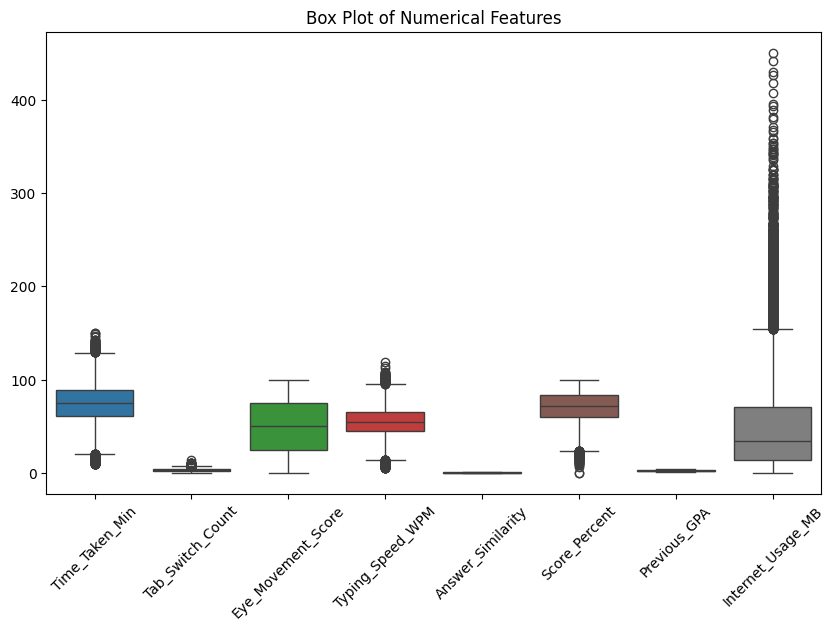

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['Time_Taken_Min',
                     'Tab_Switch_Count',
                     'Eye_Movement_Score',
                     'Typing_Speed_WPM',
                     'Answer_Similarity',
                     'Score_Percent',
                     'Previous_GPA',
                     'Internet_Usage_MB']])

plt.xticks(rotation=45)
plt.title("Box Plot of Numerical Features")
plt.show()

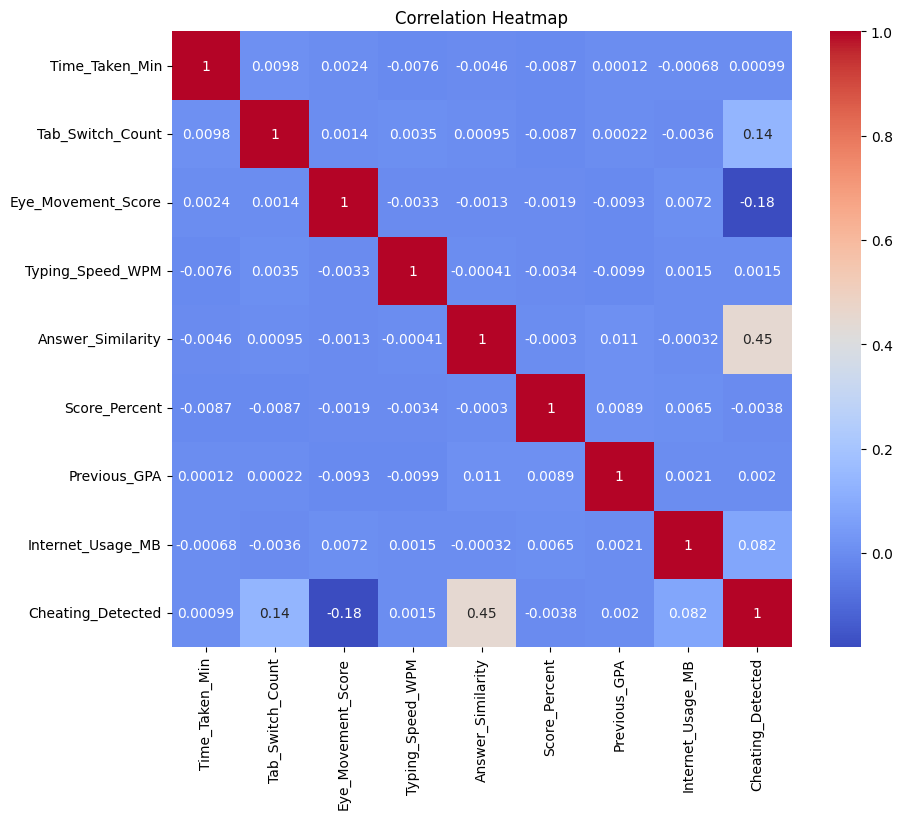

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

**FILLING NULL VALUES**

In [ ]:
df['Eye_Movement_Score']=df['Eye_Movement_Score'].fillna(df['Eye_Movement_Score'].mean())

In [ ]:
df['Typing_Speed_WPM']=df['Typing_Speed_WPM'].fillna(df['Typing_Speed_WPM'].median())

In [ ]:
df['Previous_GPA']=df['Previous_GPA'].fillna(df['Previous_GPA'].mean())

In [ ]:
df['Internet_Usage_MB']=df['Internet_Usage_MB'].fillna(df['Internet_Usage_MB'].median())

In [ ]:
df.isna().sum()

,0
Student_ID,0
Exam_Platform,0
Time_Taken_Min,0
Tab_Switch_Count,0
Eye_Movement_Score,0
Typing_Speed_WPM,0
Answer_Similarity,0
Score_Percent,0
Previous_GPA,0
Internet_Usage_MB,0


In [ ]:
df.dtypes

,0
Student_ID,object
Exam_Platform,object
Time_Taken_Min,float64
Tab_Switch_Count,int64
Eye_Movement_Score,float64
Typing_Speed_WPM,float64
Answer_Similarity,float64
Score_Percent,float64
Previous_GPA,float64
Internet_Usage_MB,float64


In [ ]:
df=df.drop(columns=['Student_ID'])
df

,Exam_Platform,Time_Taken_Min,Tab_Switch_Count,Eye_Movement_Score,Typing_Speed_WPM,Answer_Similarity,Score_Percent,Previous_GPA,Internet_Usage_MB,Cheating_Detected
0,Google Forms,62.4,2,74.50,54.8,0.3129,37.01,1.15,10.75,0
1,Zoom,117.8,5,8.46,74.9,0.2587,67.13,3.85,56.08,0
2,ExamSoft,108.3,3,80.15,47.2,0.9746,66.54,2.70,34.80,0
3,ProctorU,89.6,1,16.97,42.6,0.3956,52.15,3.27,8.80,0
4,Moodle,68.1,6,99.05,46.1,0.2302,89.74,3.51,74.76,0
...,...,...,...,...,...,...,...,...,...,...
29995,Zoom,61.9,3,79.32,73.3,0.3651,82.89,2.07,67.89,0
29996,ExamSoft,74.7,3,98.38,55.4,0.7847,50.10,1.07,4.47,0
29997,Moodle,76.3,3,19.37,61.1,0.2635,84.15,3.51,23.17,0
29998,Google Forms,101.5,5,61.20,62.2,0.6594,85.43,2.35,5.10,0


In [ ]:
print(df['Exam_Platform'].unique())

['Google Forms' 'Zoom' 'ExamSoft' 'ProctorU' 'Moodle']


In [ ]:
encoder=LabelEncoder()
df['Exam_Platform']=encoder.fit_transform(df['Exam_Platform'])

In [ ]:
print(df['Exam_Platform'].unique())

[1 4 0 3 2]


In [ ]:
df

,Exam_Platform,Time_Taken_Min,Tab_Switch_Count,Eye_Movement_Score,Typing_Speed_WPM,Answer_Similarity,Score_Percent,Previous_GPA,Internet_Usage_MB,Cheating_Detected
0,1,62.4,2,74.50,54.8,0.3129,37.01,1.15,10.75,0
1,4,117.8,5,8.46,74.9,0.2587,67.13,3.85,56.08,0
2,0,108.3,3,80.15,47.2,0.9746,66.54,2.70,34.80,0
3,3,89.6,1,16.97,42.6,0.3956,52.15,3.27,8.80,0
4,2,68.1,6,99.05,46.1,0.2302,89.74,3.51,74.76,0
...,...,...,...,...,...,...,...,...,...,...
29995,4,61.9,3,79.32,73.3,0.3651,82.89,2.07,67.89,0
29996,0,74.7,3,98.38,55.4,0.7847,50.10,1.07,4.47,0
29997,2,76.3,3,19.37,61.1,0.2635,84.15,3.51,23.17,0
29998,1,101.5,5,61.20,62.2,0.6594,85.43,2.35,5.10,0


In [ ]:
x=df.iloc[:,:9]
x

,Exam_Platform,Time_Taken_Min,Tab_Switch_Count,Eye_Movement_Score,Typing_Speed_WPM,Answer_Similarity,Score_Percent,Previous_GPA,Internet_Usage_MB
0,1,62.4,2,74.50,54.8,0.3129,37.01,1.15,10.75
1,4,117.8,5,8.46,74.9,0.2587,67.13,3.85,56.08
2,0,108.3,3,80.15,47.2,0.9746,66.54,2.70,34.80
3,3,89.6,1,16.97,42.6,0.3956,52.15,3.27,8.80
4,2,68.1,6,99.05,46.1,0.2302,89.74,3.51,74.76
...,...,...,...,...,...,...,...,...,...
29995,4,61.9,3,79.32,73.3,0.3651,82.89,2.07,67.89
29996,0,74.7,3,98.38,55.4,0.7847,50.10,1.07,4.47
29997,2,76.3,3,19.37,61.1,0.2635,84.15,3.51,23.17
29998,1,101.5,5,61.20,62.2,0.6594,85.43,2.35,5.10


In [ ]:
x.ndim

2

In [ ]:
y=df['Cheating_Detected']
y

,Cheating_Detected
0,0
1,0
2,0
3,0
4,0
...,...
29995,0
29996,0
29997,0
29998,0


In [ ]:
y.ndim

1

In [ ]:
smote=SMOTE()
x_resampled,y_resampled=smote.fit_resample(x,y)

**TRAIN TEST SPLIT**

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x_resampled,y_resampled,test_size=0.30,random_state=42)

**SCALING**

In [ ]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

**MODELING**

In [ ]:
knn=KNeighborsClassifier(n_neighbors=7)
print('Knn_model')
knn.fit(x_train,y_train)
y_pred1=knn.predict(x_test)
y_pred1


print('Score_train:',knn.score(x_train,y_train))

print('Score_test:',knn.score(x_test,y_test))

print('Confusion_matrix:',confusion_matrix(y_test,y_pred1))

print('Accuracy_Score:',accuracy_score(y_test,y_pred1))

print('Classification_report:',classification_report(y_test,y_pred1))

Knn_model
Score_train: 0.9049140253895942
Score_test: 0.8783459718711517
Confusion_matrix: [[6066 1627]
 [ 250 7486]]
Accuracy_Score: 0.8783459718711517
Classification_report:               precision    recall  f1-score   support

           0       0.96      0.79      0.87      7693
           1       0.82      0.97      0.89      7736

    accuracy                           0.88     15429
   macro avg       0.89      0.88      0.88     15429
weighted avg       0.89      0.88      0.88     15429



In [ ]:
bernoulli=BernoulliNB()
print('Bernoulli')
bernoulli.fit(x_train,y_train)
y_pred2=bernoulli.predict(x_test)
y_pred2

print('Score_train:',bernoulli.score(x_train,y_train))

print('Score_test:',bernoulli.score(x_test,y_test))

print('Confusion_matrix:',confusion_matrix(y_test,y_pred2))

print('Accuracy_Score:',accuracy_score(y_test,y_pred2))

print('Classification_report:',classification_report(y_test,y_pred2))

Bernoulli
Score_train: 0.7939942776188228
Score_test: 0.7929224188216994
Confusion_matrix: [[5494 2199]
 [ 996 6740]]
Accuracy_Score: 0.7929224188216994
Classification_report:               precision    recall  f1-score   support

           0       0.85      0.71      0.77      7693
           1       0.75      0.87      0.81      7736

    accuracy                           0.79     15429
   macro avg       0.80      0.79      0.79     15429
weighted avg       0.80      0.79      0.79     15429



In [ ]:
gaussian=GaussianNB()
print('Gaussian')
gaussian.fit(x_train,y_train)
y_pred3=gaussian.predict(x_test)
y_pred3

print('Score_train:',gaussian.score(x_train,y_train))

print('Score_test:',gaussian.score(x_test,y_test))

print('Confusion_matrix:',confusion_matrix(y_test,y_pred3))

print('Accuracy_Score:',accuracy_score(y_test,y_pred3))

print('Classification_report:',classification_report(y_test,y_pred3))

Gaussian
Score_train: 0.8293563710103058
Score_test: 0.831226910363601
Confusion_matrix: [[5820 1873]
 [ 731 7005]]
Accuracy_Score: 0.831226910363601
Classification_report:               precision    recall  f1-score   support

           0       0.89      0.76      0.82      7693
           1       0.79      0.91      0.84      7736

    accuracy                           0.83     15429
   macro avg       0.84      0.83      0.83     15429
weighted avg       0.84      0.83      0.83     15429



In [ ]:
dt=DecisionTreeClassifier(max_depth=3,criterion='entropy')
print('Decision_tree')
dt.fit(x_train,y_train)
y_pred4=dt.predict(x_test)
y_pred4

print('Score_train:',dt.score(x_train,y_train))

print('Score_test:',dt.score(x_test,y_test))

print('Confusion_matrix:',confusion_matrix(y_test,y_pred4))

print('Accuracy_Score:',accuracy_score(y_test,y_pred4))

print('Classification_report:',classification_report(y_test,y_pred4))

Decision_tree
Score_train: 0.8793022028389678
Score_test: 0.8828828828828829
Confusion_matrix: [[6749  944]
 [ 863 6873]]
Accuracy_Score: 0.8828828828828829
Classification_report:               precision    recall  f1-score   support

           0       0.89      0.88      0.88      7693
           1       0.88      0.89      0.88      7736

    accuracy                           0.88     15429
   macro avg       0.88      0.88      0.88     15429
weighted avg       0.88      0.88      0.88     15429



In [ ]:
rmfrst=RandomForestClassifier(n_estimators=100,random_state=42)
print('Random_forest')
rmfrst.fit(x_train,y_train)
y_pred5=rmfrst.predict(x_test)
y_pred5

print('Score_train:',rmfrst.score(x_train,y_train))

print('Score_test:',rmfrst.score(x_test,y_test))

print('Confusion_matrix:',confusion_matrix(y_test,y_pred5))

print('Accuracy_Score:',accuracy_score(y_test,y_pred5))

print('Classification_report:',classification_report(y_test,y_pred5))

Random_forest
Score_train: 1.0
Score_test: 0.9235854559595567
Confusion_matrix: [[6912  781]
 [ 398 7338]]
Accuracy_Score: 0.9235854559595567
Classification_report:               precision    recall  f1-score   support

           0       0.95      0.90      0.92      7693
           1       0.90      0.95      0.93      7736

    accuracy                           0.92     15429
   macro avg       0.92      0.92      0.92     15429
weighted avg       0.92      0.92      0.92     15429



In [ ]:
pickle.dump(rmfrst,open('cheating_pred_rmfrst.sav','wb'))

In [ ]:
pickle.dump(scaler,open('cheating_pred_scaler.sav','wb'))

In [ ]:
pickle.dump(encoder,open('cheating_pred_encoder.sav','wb'))